In [7]:
from matplotlib import pyplot as plt

import os
os.chdir('/engram/nklab/zy2559/transformer_brain_encoder/')
!pwd

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pickle
from engine import evaluate, train_one_epoch
from tqdm import tqdm
from scipy.stats import pearsonr as corr
from sklearn.decomposition import IncrementalPCA, PCA
from sklearn.linear_model import LinearRegression

from datasets.nsd_utils import roi_maps

data_dir = '/engram/nklab/algonauts/algonauts_2023_challenge_data/'

/engram/nklab/zy2559/transformer_brain_encoder


In [8]:

def corr_measure(data_dir, lh_fmri_test, rh_fmri_test, lh_fmri_pred, rh_fmri_pred):
    
    roi_name_maps, lh_challenge_rois, rh_challenge_rois = roi_maps(data_dir)
    # Empty correlation array of shape: (LH vertices)
    lh_correlation = np.zeros(lh_fmri_pred.shape[1])
    # Correlate each predicted LH vertex with the corresponding ground truth vertex
    for v in tqdm(range(lh_fmri_pred.shape[1])):
        lh_correlation[v] = corr(lh_fmri_pred[:,v], lh_fmri_test[:,v])[0]

    # Empty correlation array of shape: (RH vertices)
    rh_correlation = np.zeros(rh_fmri_pred.shape[1])
    # Correlate each predicted RH vertex with the corresponding ground truth vertex
    for v in tqdm(range(rh_fmri_pred.shape[1])):
        rh_correlation[v] = corr(rh_fmri_pred[:,v], rh_fmri_test[:,v])[0]

    return lh_correlation, rh_correlation

In [10]:
import torch
import os
from copy import copy
import numpy as np
from matplotlib import pyplot as plt
import cortex
import cortex.polyutils
from datasets.nsd_utils import roi_maps as _roi_maps, roi_masks as _roi_masks

roi_clusters = {'visuals':np.arange(0,7), 'bodies': np.arange(7,11), 'faces':np.arange(11,16), 'places':np.arange(16,19),'words':np.arange(19,24), 'labeled':np.arange(0,24)}

def subj_rois(subj):
    """ROI masks/names for a subject. No model checkpoint needed -
    we build the same tensors brain_encoder_wrapper exposes directly
    from the algonauts ROI files."""
    subj_data_dir = os.path.join(data_dir, 'subj' + format(subj, '02'))
    roi_name_maps, lh_challenge_rois, rh_challenge_rois = _roi_maps(subj_data_dir)
    lh_challenge_rois, rh_challenge_rois, lh_roi_names, rh_roi_names, _ = \
        _roi_masks('rois_all', roi_name_maps, lh_challenge_rois, rh_challenge_rois)

    lh_roi_clusters = []
    rh_roi_clusters = []
    for roi in roi_clusters.keys():
        lh_c = lh_challenge_rois[roi_clusters[roi]].sum(0)
        lh_c = np.clip(lh_c, a_min=None, a_max=1)
        lh_roi_clusters.append(lh_c)

        rh_c = rh_challenge_rois[roi_clusters[roi]].sum(0)
        rh_c = np.clip(rh_c, a_min=None, a_max=1)
        rh_roi_clusters.append(rh_c)

    return lh_roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters



def evaluate_roi_corr(lh_correlation, rh_correlation, subj):

    lh_roi_correlation = []
    rh_roi_correlation = []

    roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)

    roi_vs = lh_challenge_rois.sum(1) + rh_challenge_rois.sum(1)
    lh_challenge_rois = lh_challenge_rois[roi_vs > 0]
    rh_challenge_rois = rh_challenge_rois[roi_vs > 0]
    roi_names = np.array(roi_names)[roi_vs[:24] > 0].tolist()

    roi_names = roi_names
    for r in range(len(roi_names)):
        lh_roi_idx = np.where(lh_challenge_rois[r])
        rh_roi_idx = np.where(rh_challenge_rois[r])

        lh_roi_correlation.append(lh_correlation[lh_roi_idx])
        rh_roi_correlation.append(rh_correlation[rh_roi_idx])

    group_sizes = []
    for r, (cluster_name, cluster_range) in enumerate(roi_clusters.items()):
        lh_roi_idx = np.where(lh_roi_clusters[r])
        rh_roi_idx = np.where(rh_roi_clusters[r])

        lh_roi_correlation.append(lh_correlation[lh_roi_idx])
        rh_roi_correlation.append(rh_correlation[rh_roi_idx])

        roi_names.append(cluster_name)

        group_sizes.append(torch.sum(roi_vs[cluster_range] > 0).item())

    group_sizes.pop()
    group_sizes.append(5)
    group_sizes.append(1)


    roi_names.append('All_vertices')
    lh_roi_correlation.append(lh_correlation)
    rh_roi_correlation.append(rh_correlation)

    # Create the plot
    lh_mean_roi_correlation = [np.mean(np.nan_to_num(np.array(lh_roi_correlation[r]), copy=True, nan=0.0, posinf=None, neginf=None))
        for r in range(len(lh_roi_correlation))]
    rh_mean_roi_correlation = [np.mean(np.nan_to_num(np.array(rh_roi_correlation[r]), copy=True, nan=0.0, posinf=None, neginf=None))
        for r in range(len(rh_roi_correlation))]

    roi_names[-2] = 'All areas'

    combined_mean_roi_correlation = [
        np.mean(np.concatenate([
            np.nan_to_num(np.array(lh_roi_correlation[r]), nan=0.0),
            np.nan_to_num(np.array(rh_roi_correlation[r]), nan=0.0)
        ]))
        for r in range(len(lh_roi_correlation))
    ]


    # Build the dictionary
    result_dict_json = {
        name: {
            "lh": np.nan_to_num(val1, nan=0.0).tolist(),
            "rh": np.nan_to_num(val2, nan=0.0).tolist(),
            "combined": np.nan_to_num(val3, nan=0.0).tolist()
            }
            for name, val1, val2, val3 in zip(roi_names, lh_mean_roi_correlation, rh_mean_roi_correlation, combined_mean_roi_correlation)
        }

    return result_dict_json, lh_roi_correlation, rh_roi_correlation, lh_mean_roi_correlation, rh_mean_roi_correlation, roi_names, group_sizes



def plot_roi_correlation(lh_roi_correlation, rh_roi_correlation, roi_names, group_sizes, lay_res_dir, save_file='test_res', font_size=(20, 16), ylim=(0.0, 1.0)):

    # Create the plot
    lh_mean_roi_correlation = [np.mean(np.nan_to_num(np.array(lh_roi_correlation[r]), copy=True, nan=0.0, posinf=None, neginf=None))
        for r in range(len(lh_roi_correlation))]
    rh_mean_roi_correlation = [np.mean(np.nan_to_num(np.array(rh_roi_correlation[r]), copy=True, nan=0.0, posinf=None, neginf=None))
        for r in range(len(rh_roi_correlation))]

    roi_names[-2] = 'All areas'
    plt.rcParams.update({'font.size': font_size[0]})

    fig = plt.figure(figsize=(18,6))

    #group_sizes = [7, 3, 3, 3, 4, 5, 1]
    gap = 1  # space between groups
    width = 0.30

    # Compute x positions with gaps
    x = []
    current_pos = 0
    for size in group_sizes:
        x.extend(list(np.arange(current_pos, current_pos + size)))
        current_pos += size + gap
    x = np.array(x)

    # Remove the last element from names and data (as in your original code)
    roi_labels = roi_names[:-1]
    lh_vals = lh_mean_roi_correlation[:-1]
    rh_vals = rh_mean_roi_correlation[:-1]

    # Plot bars
    plt.bar(x - width/2, lh_vals, width, label='Left Hemisphere')
    plt.bar(x + width/2, rh_vals, width, label='Right Hemisphere')

    plt.xlim(left=min(x)-.5, right=max(x)+.5)
    plt.ylim(bottom=ylim[0], top=ylim[1])
    plt.xlabel('ROIs')
    plt.xticks(ticks=x, labels=roi_labels, rotation=75)
    plt.ylabel('Encoding Accuracy')
    plt.legend(frameon=True, loc=2, fontsize=font_size[1])
    plt.tight_layout()
    plt.show()

        #fig.savefig('figures/detr_dino_8_visuals_16.pdf', format='pdf', bbox_inches="tight")
    fig.savefig(lay_res_dir+save_file+'.svg', dpi=300, bbox_inches="tight")
    fig.savefig(lay_res_dir+save_file+'.png', dpi=300, bbox_inches="tight")


def plot_pycortex(lh_challenge_rois, rh_challenge_rois, lh_correlation, rh_correlation, save_file='p_test', ylim=(-0.0, 1.0)):

    """ Plot data on a flattened brain surface using pycortex."""

    lh_challenge = lh_challenge_rois[:24].sum(0).numpy().astype(float)
    lh_correlation[lh_challenge == 0] = np.nan

    rh_challenge = rh_challenge_rois[:24].sum(0).numpy().astype(float)
    rh_correlation[rh_challenge == 0] = np.nan

    # =============================================================================
    # Map the data to fsaverage space
    # =============================================================================
    # pycortex requires data in fsaverage space, so here you map the vertices from
    # Challenge space into fsaverage space. The voxels not used in the Challenge
    # are given NaN values, so that pycortex ignores them for the plotting.
    # "ls_scores" and "rh_scores" are lists with 8 elements, one for each subject.
    # These elements consist of vectors of length N, where N is the vertex amount
    # for each subject and hemisphere, and each vector component consists of the
    # prediction accuracy for that vertex.

    #challenge_data_dir = '../algonauts_2023_challenge_data'
    challenge_data_dir = '/engram/nklab/algonauts/algonauts_2023_challenge_data/'
    lh_fsaverage = []
    rh_fsaverage = []
    subjects = [1]
    for s, sub in enumerate(subjects):
        lh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
            'roi_masks', 'lh.all-vertices_fsaverage_space.npy')
        rh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
            'roi_masks', 'rh.all-vertices_fsaverage_space.npy')
        lh_fsaverage_all_vertices = np.load(lh_mask_dir)
        rh_fsaverage_all_vertices = np.load(rh_mask_dir)
        lh_fsavg = np.empty((len(lh_fsaverage_all_vertices)))
        lh_fsavg[:] = np.nan
        lh_fsavg[np.where(lh_fsaverage_all_vertices)[0]] = lh_correlation #lh_scores[s]
        lh_fsaverage.append(copy(lh_fsavg))
        rh_fsavg = np.empty((len(rh_fsaverage_all_vertices)))
        rh_fsavg[:] = np.nan
        rh_fsavg[np.where(rh_fsaverage_all_vertices)[0]] = rh_correlation #rh_scores[s]
        rh_fsaverage.append(copy(rh_fsavg))

        break

    # Average the scores across subjects
    lh_fsaverage = np.nanmean(lh_fsaverage, 0)
    rh_fsaverage = np.nanmean(rh_fsaverage, 0)


    # =============================================================================
    # Plot parameters for colorbar
    # =============================================================================
    plt.rc('xtick', labelsize=19)
    plt.rc('ytick', labelsize=19)


    # =============================================================================
    # Plot the results on brain surfaces
    # =============================================================================
    subject = 'fsaverage'
    data = np.append(lh_fsaverage, rh_fsaverage) #* 100
    vertex_data = cortex.Vertex(data, subject, cmap='RdBu_r', vmin=ylim[0], vmax=ylim[1])
    cortex.quickshow(vertex_data, with_curvature=True)
    plt.savefig('images/' + save_file + '.svg', dpi=300)
    plt.savefig('images/' + save_file + '.png', dpi=300)
    plt.show()

### build one evaluation function for all models

In [11]:
import json
def evaluate_model(args):

    lh_corr = []
    rh_corr = []

    for subj in args.subjects:
        print(f'subj: {subj}')
        # class argObj:
        #     def __init__(self, data_dir, subj):

        args.subj = format(subj, '02')
        args.data_dir = os.path.join(data_dir, 'subj'+args.subj)

        roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)

        #roi_name_maps, lh_challenge_rois, rh_challenge_rois = roi_maps(args.data_dir)

        if args.split == 'val':
        
            lh_pred = []
            rh_pred = []
            lh_correlation = []
            rh_correlation = []

            lay_res_dir = f'./results/nsd_test/{args.arch}/subj_{args.subj}/{args.readout_res}/enc_{args.enc_output_layer}/'
            
            for run in args.runs:
                
                subj_res_dir = lay_res_dir + f'/run_{run}/'
                if args.verbose:
                    print(f'run: {run}')
                    print(subj_res_dir)
                
                idxs = np.load(subj_res_dir + '/idxs.npy')  

                num_train = int(np.round(len(idxs) / 100 * 90))
                idxs_train, idxs_val = idxs[:num_train], idxs[num_train:]

                fmri_dir = os.path.join(args.data_dir, 'training_split', 'training_fmri')
                lh_fmri = np.load(os.path.join(fmri_dir, 'lh_training_fmri.npy'))
                rh_fmri = np.load(os.path.join(fmri_dir, 'rh_training_fmri.npy'))

                lh_fmri_train = lh_fmri[idxs_train]
                lh_fmri_val = lh_fmri[idxs_val]
                rh_fmri_train = rh_fmri[idxs_train]
                rh_fmri_val = rh_fmri[idxs_val]

                lh_fmri_pred = np.load(subj_res_dir + 'lh_fmri_val_pred.npy')
                rh_fmri_pred = np.load(subj_res_dir + 'rh_fmri_val_pred.npy')

                lh_correlation_run, rh_correlation_run = corr_measure(args.data_dir, lh_fmri_val, rh_fmri_val, lh_fmri_pred, rh_fmri_pred)
                
                if args.save_val_corr:
                    print(lay_res_dir)
                    np.save(subj_res_dir + 'lh_val_corr.npy', lh_correlation_run)
                    np.save(subj_res_dir + 'rh_val_corr.npy', rh_correlation_run)
                
                lh_correlation.append(lh_correlation_run)
                rh_correlation.append(rh_correlation_run)

            lh_correlation = np.mean(np.array(lh_correlation), axis=0)
            rh_correlation = np.mean(np.array(rh_correlation), axis=0)

            if args.save_ave:
                print(lay_res_dir)
                np.save(lay_res_dir + 'lh_val_corr.npy', lh_correlation)
                np.save(lay_res_dir + 'rh_val_corr.npy', rh_correlation)

        elif args.split == 'test':
            fmri_dir = os.path.join(args.data_dir, 'test_split', 'test_fmri')
            lh_fmri_test = np.load(os.path.join(fmri_dir, 'lh_test_fmri.npy'))
            rh_fmri_test = np.load(os.path.join(fmri_dir, 'rh_test_fmri.npy'))

            lh_pred = []
            rh_pred = []
            for run in args.runs:
                
                lay_res_dir =  f'./results/nsd_test/{args.arch}/subj_{args.subj}/{args.readout_res}/enc_{args.enc_output_layer}/'
                
                subj_res_dir = lay_res_dir + f'run_{run}/'
            
                if args.verbose:
                    print(f'run: {run}')
                    print(subj_res_dir)
                    
                if args.learn_reg:
                    feature_dir = './saved_image_features/'
                        
                    subject_feature_dir =  os.path.join(feature_dir, args.feature_name,format(subj, '02'))
                    save_dir = subject_feature_dir + '/pca_run' + str(run)
                    idxs = np.load(save_dir + '/idxs.npy') 
                    num_train = int(np.round(len(idxs) / 100 * 90))
                    idxs_train, idxs_val = idxs[:num_train], idxs[num_train:] 

                    features_train = np.load(save_dir + '/train.npy')
                    features_val = np.load(save_dir + '/val.npy')
                    features_test = np.load(save_dir + '/test.npy')

                    fmri_dir = os.path.join(args.data_dir, 'training_split', 'training_fmri')
                    lh_fmri = np.load(os.path.join(fmri_dir, 'lh_training_fmri.npy'))
                    rh_fmri = np.load(os.path.join(fmri_dir, 'rh_training_fmri.npy'))

                    lh_fmri_train = lh_fmri[idxs_train]
                    lh_fmri_val = lh_fmri[idxs_val]
                    rh_fmri_train = rh_fmri[idxs_train]
                    rh_fmri_val = rh_fmri[idxs_val]

                    # Fit linear regressions on the training data
                    reg_lh = LinearRegression().fit(features_train, lh_fmri_train)
                    reg_rh = LinearRegression().fit(features_train, rh_fmri_train)
                    # Use fitted linear regressions to predict the validation and test fMRI data
                    lh_fmri_val_pred = reg_lh.predict(features_val)
                    lh_fmri_test_pred = reg_lh.predict(features_test)
                    rh_fmri_val_pred = reg_rh.predict(features_val)
                    rh_fmri_test_pred = reg_rh.predict(features_test)

                    lh_pred.append(lh_fmri_test_pred)
                    rh_pred.append(rh_fmri_test_pred)

                else:
                    lh_pred.append(np.load(subj_res_dir + 'lh_pred_test.npy'))
                    rh_pred.append(np.load(subj_res_dir + 'rh_pred_test.npy'))
            
            lh_fmri_pred = np.mean(lh_pred, axis=0)
            rh_fmri_pred = np.mean(rh_pred, axis=0)

            if args.save_ave:
                np.save(lay_res_dir + 'lh_pred_test.npy', lh_fmri_pred)
                np.save(lay_res_dir + 'rh_pred_test.npy', rh_fmri_pred)

            fmri_noise_dir = os.path.join(args.data_dir, 'test_split', 'noise_ceiling')
            lh_nc = np.load(os.path.join(fmri_noise_dir, 'lh_noise_ceiling.npy'))
            rh_nc = np.load(os.path.join(fmri_noise_dir, 'rh_noise_ceiling.npy'))

            lh_correlation, rh_correlation = corr_measure(args.data_dir, lh_fmri_test, rh_fmri_test, lh_fmri_pred, rh_fmri_pred)

        lh_correlation[lh_correlation<0] = 0
        rh_correlation[rh_correlation<0] = 0

        if args.split == 'test' and args.measure == 'exp_var':
            lh_r2 = lh_correlation ** 2
            rh_r2 = rh_correlation ** 2

            lh_nc[lh_nc==0] = 1e-14
            rh_nc[rh_nc==0] = 1e-14

            # Compute the noise-ceiling-normalized encoding accuracy
            expl_var_lh = np.divide(lh_r2, lh_nc)
            expl_var_rh = np.divide(rh_r2, rh_nc)

            # Set the noise-ceiling-normalized encoding accuracy to 1 for those vertices
            # in which the r2 scores are higher than the noise ceiling, to prevent
            # encoding accuracy values higher than 100%
            expl_var_lh[expl_var_lh>1] = 1
            expl_var_rh[expl_var_rh>1] = 1

            lh_correlation = expl_var_lh
            rh_correlation = expl_var_rh
        
        
        result_dict_json, lh_roi_correlation, rh_roi_correlation, lh_mean_roi_correlation, rh_mean_roi_correlation, roi_names, group_sizes  = evaluate_roi_corr(lh_correlation, rh_correlation, subj=subj)
        plot_roi_correlation(lh_roi_correlation, rh_roi_correlation, roi_names, group_sizes, lay_res_dir=lay_res_dir, save_file='tr')
        

        with open(lay_res_dir +"results.json", "w") as f:
            json.dump(result_dict_json, f, indent=2)
        

        lh_corr.append(lh_mean_roi_correlation[-1])
        rh_corr.append(rh_mean_roi_correlation[-1])

        if args.verbose:
            print(f'subj: {subj}   lh_corr: {lh_mean_roi_correlation[-1]}   rh_corr: {rh_mean_roi_correlation[-1]}')

    if args.verbose:
        print(f'lh_corr_mean: {np.array(lh_corr).mean()}   rh_corr_mean: {np.array(rh_corr).mean()}')

    return lh_corr, rh_corr, lh_roi_correlation, rh_roi_correlation, roi_names, lay_res_dir, group_sizes 

subj: 1
run: 1
./results/nsd_test/dinov2_q_transformer/subj_01/rois_all/enc_1/run_1/


100%|██████████| 20544/20544 [00:04<00:00, 4514.81it/s]


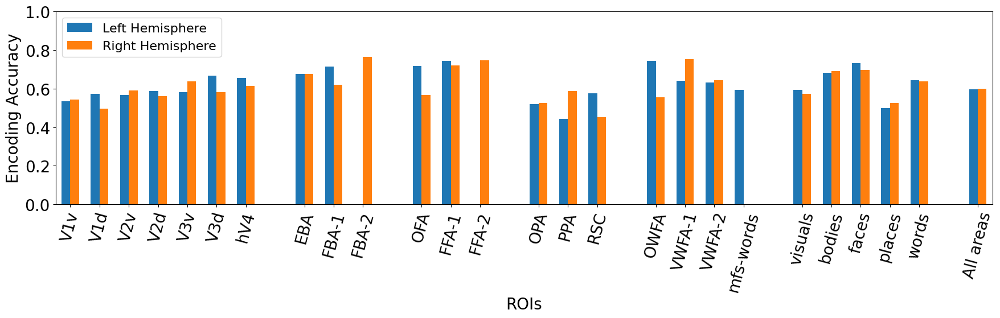

subj: 1   lh_corr: 0.5590963476899748   rh_corr: 0.5490791765557862
lh_corr_mean: 0.5590963476899748   rh_corr_mean: 0.5490791765557862


In [6]:


# arch = 'dinov2_q_transformer' #'resnet50_transformer' # dinov2_q_transformer
# feature_name = 'dinov2_q_last' # 'resnet50'  # dinov2_q_last

class model_argObj:
    def __init__(self, arch, feature_name, readout_res, enc_output_layer, learn_reg):

        self.arch = arch
        self.feature_name = feature_name
        self.readout_res = readout_res
        self.enc_output_layer = enc_output_layer
        self.learn_reg = learn_reg

        self.subjects = np.arange(1,2)
        self.runs = np.arange(1,11)

        self.split = 'test' # test
        self.measure = 'exp_var'  # 'exp_var' 'corr'
        self.verbose = 1
        self.plot_figs = 1

        self.save_fig = None # 'figures/detr_dino_8_visuals_16.pdf'
        self.save_mean_act = None # 'figures/detr_dino_8_visuals_16.jpg'

        self.save_ave = 0
        self.save_val_corr = 0


qargs = []

qargs.append(['dinov2_q_transformer', 'dinov2_q_last', 'rois_all', 1, 0])


for m in range(len(qargs)):
    args = model_argObj(*qargs[m])
    evaluate_model(args)

In [ ]:
class model_argObj:
    def __init__(self, arch, feature_name, readout_res, enc_output_layer, learn_reg):

        self.arch = arch
        self.feature_name = feature_name
        self.readout_res = readout_res
        self.enc_output_layer = enc_output_layer
        self.learn_reg = learn_reg

        self.subjects = np.arange(7,8)
        self.runs = np.arange(1,11)

        self.split = 'test' # test
        self.measure = 'exp_var'  # 'exp_var' 'corr'
        self.verbose = 1
        self.plot_figs = 1

        self.save_fig = None # 'figures/detr_dino_8_visuals_16.pdf'
        self.save_mean_act = None # 'figures/detr_dino_8_visuals_16.jpg'

        self.save_ave = 0
        self.save_val_corr = 0


qargs = []

In [ ]:
qargs = ['dinov2_q_transformer', 'dinov2_q_last', 'rois_all', 1, 0]
args = model_argObj(*qargs)
print(args)
lh_corr, rh_corr, lh_roi_correlation_t, rh_roi_correlation_t, roi_names, lay_res_dir, group_sizes  = evaluate_model(args)
#plot_roi_correlation(lh_roi_correlation_t, rh_roi_correlation_t, roi_names, group_sizes, lay_res_dir='./images/', save_file='s2_tv', ylim=(0 ))

qargs = ['clip_transformer', 'clip', 'rois_all', 1, 0]
#qargs = ['dinov2_q_linear', 'dinov2_q_last', 'voxels', 1, 0]
args = model_argObj(*qargs)
print(args)
lh_corr, rh_corr, lh_roi_correlation_r, rh_roi_correlation_r, roi_names, lay_res_dir, group_sizes  = evaluate_model(args)
#plot_roi_correlation(lh_roi_correlation_r, rh_roi_correlation_r, roi_names, group_sizes, lay_res_dir='./images/', save_file='s2_tr', ylim=(0, 1))


lh_roi_correlation = [a - b for a, b in zip(lh_roi_correlation_t, lh_roi_correlation_r)]
rh_roi_correlation = [a - b for a, b in zip(rh_roi_correlation_t, rh_roi_correlation_r)]

plot_roi_correlation(lh_roi_correlation, rh_roi_correlation, roi_names, group_sizes, lay_res_dir='./images/', save_file='s7_clip_tr-tr', ylim=(-0.2, 0.4))

In [ ]:
subj = args.subjects[0]
roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)
plot_pycortex(lh_challenge_rois, rh_challenge_rois, lh_roi_correlation[-1], rh_roi_correlation[-1], save_file='/subj_2/tr-l_correct')

Setting _INKSCAPE_GC=disable as a workaround for broken libgc
(process:160928): Gtk-WARNING **: 10:40:31.444: Locale not supported by C library.
	Using the fallback 'C' locale.
Unable to init server: Could not connect: Connection refused
(ld-linux-x86-64.so.2:160928): glibmm-WARNING **: 10:40:32.105: Failed to wrap object of type 'GtkRecentManager'. Hint: this error is commonly caused by failing to call a library init() function.


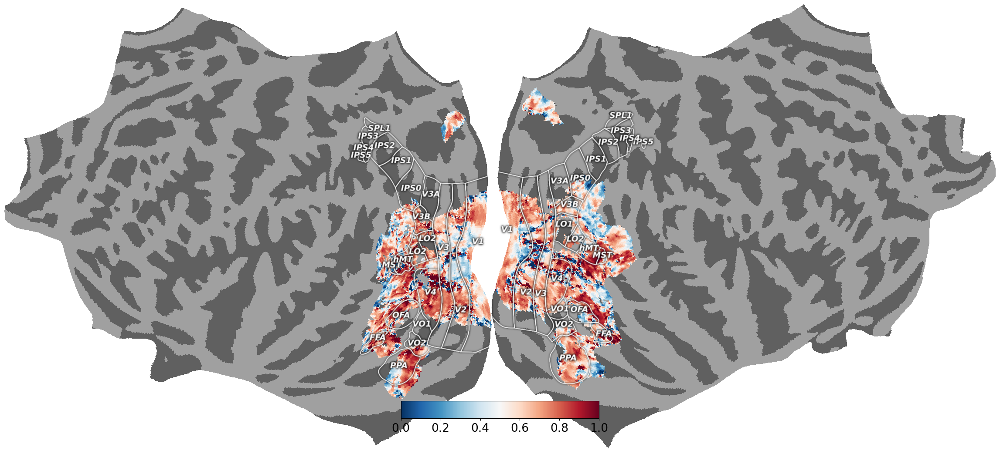

In [ ]:
plot_pycortex(lh_challenge_rois, rh_challenge_rois, lh_roi_correlation_t[-1], rh_roi_correlation_t[-1], save_file='/subj_2/tr')

## combine all the test predictions based on softmax 

In [ ]:
from scipy.special import softmax

def evaluate_combined_model():

    lh_corr = []
    rh_corr = []

    for subj in args.subjects:
        print(f'subj: {subj}')
        # class argObj:
        #     def __init__(self, data_dir, subj):

        args.subj = format(subj, '02')
        args.data_dir = os.path.join(data_dir, 'subj'+args.subj)

        #roi_name_maps, lh_challenge_rois, rh_challenge_rois = roi_maps(args.data_dir)
        roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)

        roi_vs = lh_challenge_rois.sum(1) + rh_challenge_rois.sum(1)
        lh_challenge_rois = lh_challenge_rois[roi_vs > 0]
        rh_challenge_rois = rh_challenge_rois[roi_vs > 0]
        roi_names = np.array(roi_names)[roi_vs[:24] > 0].tolist()

        lh_correlation = []
        rh_correlation = []

        lh_pred_test = []
        rh_pred_test = []

        lh_pred_corr = []
        rh_pred_corr = [] 
        
        
        for lay in [1, 3, 5, 7, 9, 11]:
            lay_res_dir = f'./results/nsd_test/{args.arch}/subj_{args.subj}/{args.readout_res}/enc_{lay}/'
            
            lh_correlation_lay = []
            rh_correlation_lay = []

            lh_fmri_pred_lay = []
            rh_fmri_pred_lay = []

            for run in args.runs:
                run_res_dir = lay_res_dir + f'/run_{run}/'

                lh_correlation = np.load(run_res_dir + 'lh_val_corr.npy')
                rh_correlation = np.load(run_res_dir + 'rh_val_corr.npy')

                lh_correlation_lay.append(lh_correlation)
                rh_correlation_lay.append(rh_correlation)

                lh_fmri_pred = np.load(run_res_dir + 'lh_pred_test.npy')
                rh_fmri_pred = np.load(run_res_dir + 'rh_pred_test.npy')

                lh_fmri_pred_lay.append(lh_fmri_pred)
                rh_fmri_pred_lay.append(rh_fmri_pred)

            lh_correlation_lay = np.array(lh_correlation_lay).mean(0)
            rh_correlation_lay = np.array(rh_correlation_lay).mean(0)

            lh_fmri_pred_lay = np.array(lh_fmri_pred_lay).mean(0)
            rh_fmri_pred_lay = np.array(rh_fmri_pred_lay).mean(0)

            lh_pred_corr.append(lh_correlation_lay)
            rh_pred_corr.append(rh_correlation_lay)

            lh_pred_test.append(lh_fmri_pred_lay)
            rh_pred_test.append(rh_fmri_pred_lay)

        lh_pred_corr = np.array(lh_pred_corr)
        rh_pred_corr = np.array(rh_pred_corr)

        lh_pred_test = np.array(lh_pred_test)
        rh_pred_test = np.array(rh_pred_test)

        lh_corr_sm = softmax(50*lh_pred_corr, axis=0)
        lh_corr_sm = np.tile(np.expand_dims(lh_corr_sm,1), (1,lh_pred_test.shape[1],1))
        lh_pred = np.multiply(lh_corr_sm, lh_pred_test).sum(0)
        
        rh_corr_sm = softmax(50*rh_pred_corr, axis=0)
        rh_corr_sm = np.tile(np.expand_dims(rh_corr_sm,1), (1,rh_pred_test.shape[1],1))
        print(rh_corr_sm.shape)
        rh_pred = np.multiply(rh_corr_sm, rh_pred_test).sum(0)


        fmri_dir = os.path.join(args.data_dir, 'test_split', 'test_fmri')
        lh_fmri_test = np.load(os.path.join(fmri_dir, 'lh_test_fmri.npy'))
        rh_fmri_test = np.load(os.path.join(fmri_dir, 'rh_test_fmri.npy'))

        fmri_noise_dir = os.path.join(args.data_dir, 'test_split', 'noise_ceiling')
        lh_nc = np.load(os.path.join(fmri_noise_dir, 'lh_noise_ceiling.npy'))
        rh_nc = np.load(os.path.join(fmri_noise_dir, 'rh_noise_ceiling.npy'))

        lh_correlation, rh_correlation = corr_measure(args.data_dir, lh_fmri_test, rh_fmri_test, lh_pred, rh_pred)

        lh_correlation[lh_correlation<0] = 0
        rh_correlation[rh_correlation<0] = 0

        #if args.split == 'test' and args.measure == 'exp_var':
        lh_r2 = lh_correlation ** 2
        rh_r2 = rh_correlation ** 2

        lh_nc[lh_nc==0] = 1e-14
        rh_nc[rh_nc==0] = 1e-14

        # Compute the noise-ceiling-normalized encoding accuracy
        expl_var_lh = np.divide(lh_r2, lh_nc)
        expl_var_rh = np.divide(rh_r2, rh_nc)

        # Set the noise-ceiling-normalized encoding accuracy to 1 for those vertices
        # in which the r2 scores are higher than the noise ceiling, to prevent
        # encoding accuracy values higher than 100%
        expl_var_lh[expl_var_lh>1] = 1
        expl_var_rh[expl_var_rh>1] = 1

        lh_correlation = expl_var_lh
        rh_correlation = expl_var_rh

        result_dict_json, lh_roi_correlation, rh_roi_correlation, lh_mean_roi_correlation, rh_mean_roi_correlation, roi_names  = evaluate_roi_corr(lh_correlation, rh_correlation, subj=1)

        #result_dict_json, lh_roi_correlation, rh_roi_correlation, roi_names = evaluate_roi_corr(lh_correlation, rh_correlation, roi_names)
        plot_roi_correlation(lh_roi_correlation, rh_roi_correlation, roi_names, lay_res_dir, save_file='test_res')

        with open(lay_res_dir +"results.json", "w") as f:
            json.dump(result_dict_json, f, indent=2)

        
        plt.rcParams.update({'font.size': 20})
        
        lh_corr.append(lh_mean_roi_correlation[-1])
        rh_corr.append(rh_mean_roi_correlation[-1])

        if args.verbose:
            print(f'subj: {subj}   lh_corr: {lh_mean_roi_correlation[-1]}   rh_corr: {rh_mean_roi_correlation[-1]}')

    if args.verbose:
        print(f'lh_corr_mean: {np.array(lh_corr).mean()}   rh_corr_mean: {np.array(rh_corr).mean()}')

    return lh_corr, rh_corr, lh_roi_correlation, rh_roi_correlation, roi_names, lay_res_dir


#evaluate_combined_model()

Save figures related to subj 1

subj: 2


Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


(6, 159, 20544)


100%|██████████| 20544/20544 [00:12<00:00, 1687.11it/s]
Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


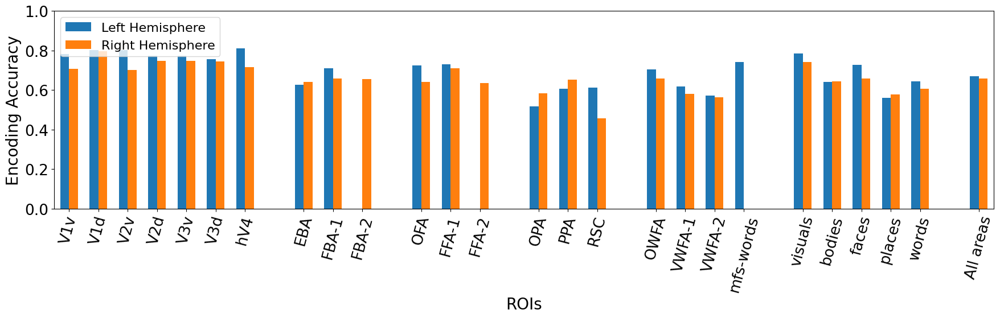

subj: 2   lh_corr: 0.6285629292137833   rh_corr: 0.6131732245102208
lh_corr_mean: 0.6285629292137833   rh_corr_mean: 0.6131732245102208


In [ ]:
class model_argObj:
    def __init__(self, arch, feature_name, readout_res, enc_output_layer, learn_reg):

        self.arch = arch
        self.feature_name = feature_name
        self.readout_res = readout_res
        self.enc_output_layer = enc_output_layer
        self.learn_reg = learn_reg

        self.subjects = np.arange(2,3)
        self.runs = np.arange(1,11)
        
        self.split = 'test' # test
        self.measure = 'exp_var'  # 'corr'
        self.verbose = 1
        self.plot_figs = 1

        self.save_fig = None # 'figures/detr_dino_8_visuals_16.pdf'
        self.save_mean_act = None # 'figures/detr_dino_8_visuals_16.jpg'

        self.save_ave = 0
        self.save_val_corr = 0


qargs = []
qargs.append(['dinov2_q_transformer', 'dinov2_q_last', 'voxels', 1, 0])

args = model_argObj(*qargs[0])

lh_corr, rh_corr, lh_roi_correlation_tc, rh_roi_correlation_tc, roi_names, lay_res_dir = evaluate_combined_model()
#plot_roi_correlation(lh_roi_correlation_tc, rh_roi_correlation_tc, roi_names, lay_res_dir, save_file='tc', font_size=(20, 12))

### plot the difference between two runs

subj: 2


Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


run: 1
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_1/
run: 2
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_2/
run: 3
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_3/
run: 4
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_4/
run: 5
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_5/
run: 6
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_6/
run: 7
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_7/
run: 8
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_8/
run: 9
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_9/
run: 10
./results/nsd_test/dinov2_q_transformer/subj_02/voxels/enc_1/run_10/


100%|██████████| 20544/20544 [00:12<00:00, 1691.01it/s]
Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


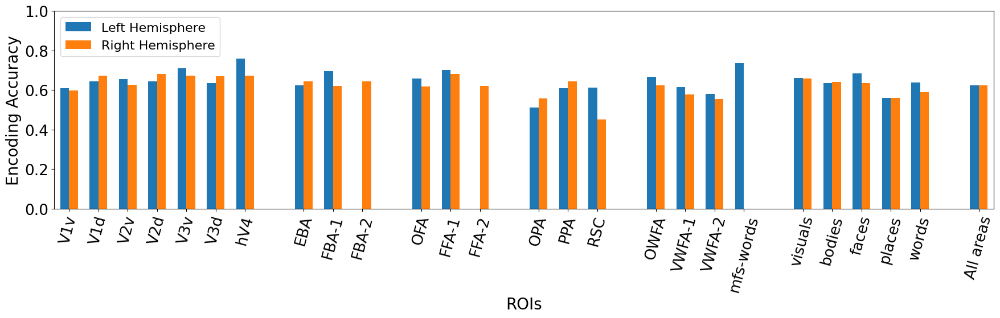

subj: 2   lh_corr: 0.5921551419044323   rh_corr: 0.5836765278442985
lh_corr_mean: 0.5921551419044323   rh_corr_mean: 0.5836765278442985


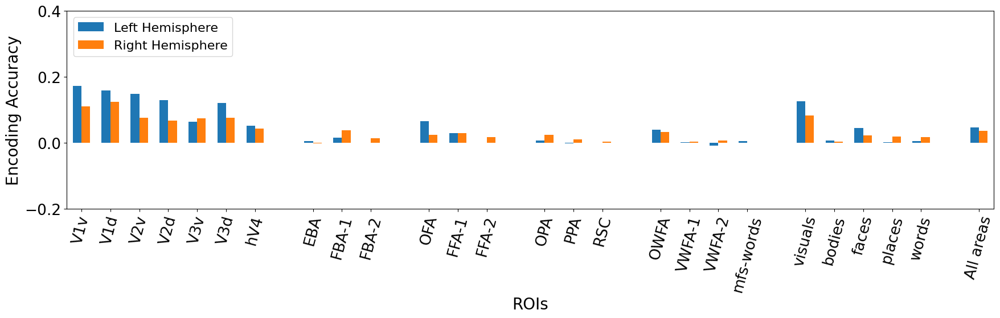

In [ ]:
qargs = ['dinov2_q_transformer', 'dinov2_q_last', 'voxels', 1, 0]
args = model_argObj(*qargs)
lh_corr, rh_corr, lh_roi_correlation_t, rh_roi_correlation_t, roi_names, lay_res_dir = evaluate_model(args)

lh_roi_correlation = [a - b for a, b in zip(lh_roi_correlation_tc, lh_roi_correlation_t)]
rh_roi_correlation = [a - b for a, b in zip(rh_roi_correlation_tc, rh_roi_correlation_t)]

plot_roi_correlation(lh_roi_correlation, rh_roi_correlation, roi_names, lay_res_dir='./images/', save_file='tc-t', ylim=(-0.2, 0.4))

Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


Setting _INKSCAPE_GC=disable as a workaround for broken libgc
(process:166416): Gtk-WARNING **: 10:44:55.886: Locale not supported by C library.
	Using the fallback 'C' locale.
Unable to init server: Could not connect: Connection refused
(ld-linux-x86-64.so.2:166416): glibmm-WARNING **: 10:44:56.819: Failed to wrap object of type 'GtkRecentManager'. Hint: this error is commonly caused by failing to call a library init() function.


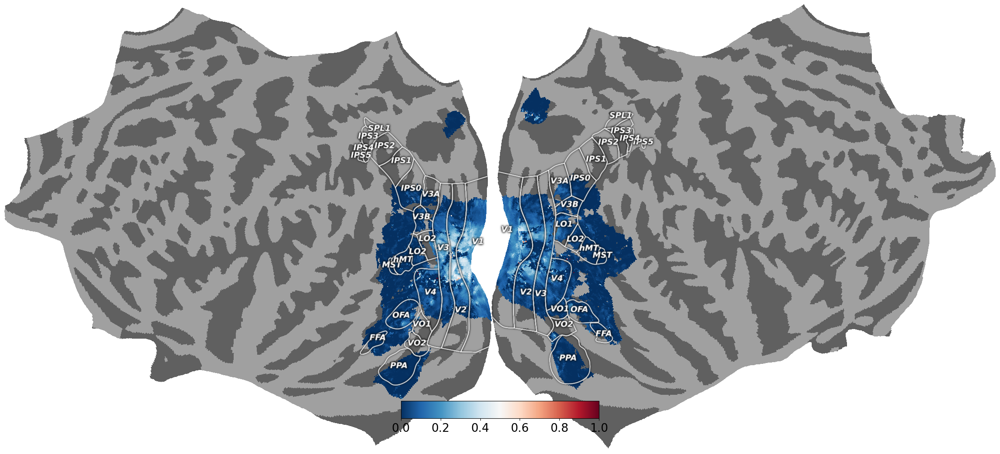

In [ ]:
subj = 1
roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)
plot_pycortex(lh_challenge_rois, rh_challenge_rois, lh_roi_correlation[-1], rh_roi_correlation[-1], save_file='subj_2/tc-tv', ylim=(0, 1))

Setting _INKSCAPE_GC=disable as a workaround for broken libgc
(process:167562): Gtk-WARNING **: 10:45:41.238: Locale not supported by C library.
	Using the fallback 'C' locale.
Unable to init server: Could not connect: Connection refused
(ld-linux-x86-64.so.2:167562): glibmm-WARNING **: 10:45:41.877: Failed to wrap object of type 'GtkRecentManager'. Hint: this error is commonly caused by failing to call a library init() function.


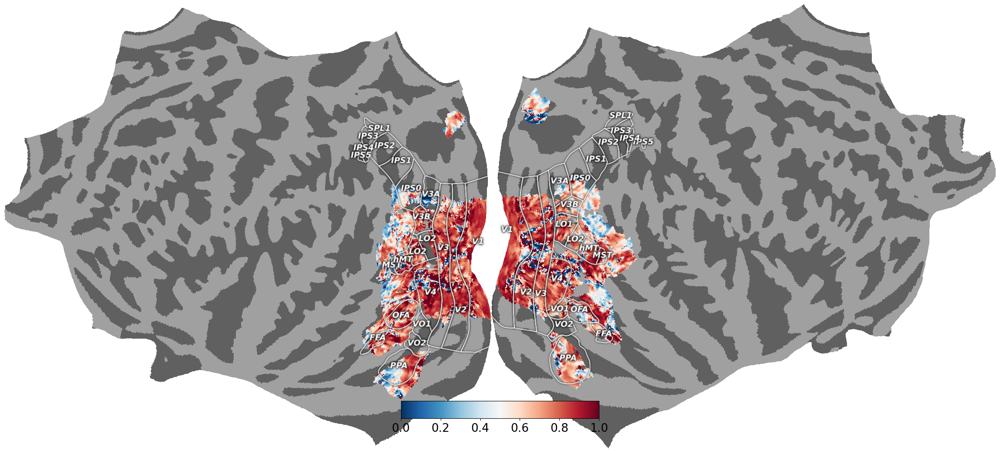

In [ ]:
plot_pycortex(lh_challenge_rois, rh_challenge_rois, lh_roi_correlation_tc[-1], rh_roi_correlation_tc[-1], save_file='subj_2/tc', ylim=(0, 1))

### plot which layer was best at predicting each voxel

In [ ]:
split = 'test' # test
measure = 'exp_var'  # 'corr'

arch = 'dinov2_q_transformer' #'resnet50_transformer' # dinov2_q_transformer
feature_name = 'dinov2_q_last' # 'resnet50'  # dinov2_q_last

# arch = 'resnet50_transformer' #'resnet50_transformer' # dinov2_q_transformer
# feature_name = 'resnet50' # 'resnet50'  # dinov2_q_last

readout_res = 'rois_all'  # [streams_inc', 'visuals', 'bodies', 'places', 'faces', 'words']
enc_output_layer = 1

learn_reg = 0


lh_corr = []
rh_corr = []

for subj in [1]: #range(1,9):
    print(f'subj: {subj}')
    class argObj:
        def __init__(self, data_dir, subj):

            self.subj = format(subj, '02')
            self.data_dir = os.path.join(data_dir, 'subj'+self.subj)

    args = argObj(data_dir, subj)

    roi_name_maps, lh_challenge_rois, rh_challenge_rois = roi_maps(args.data_dir)

    fmri_dir = os.path.join(args.data_dir, 'test_split', 'test_fmri')
    lh_fmri_test = np.load(os.path.join(fmri_dir, 'lh_test_fmri.npy'))
    rh_fmri_test = np.load(os.path.join(fmri_dir, 'rh_test_fmri.npy'))

    fmri_noise_dir = os.path.join(args.data_dir, 'test_split', 'noise_ceiling')
    lh_nc = np.load(os.path.join(fmri_noise_dir, 'lh_noise_ceiling.npy'))
    rh_nc = np.load(os.path.join(fmri_noise_dir, 'rh_noise_ceiling.npy'))

    lh_correlation_all_layers = []
    rh_correlation_all_layers = []

    for enc_output_layer in range(1, 13): # [1, 3, 5, 7, 9, 11]: #
        
        print(f'enc_output_layer: {enc_output_layer}')
        lh_pred = []
        rh_pred = []
        for run in range(1, 11):
            print(f'run: {run}')
            subj_res_dir = f'./results/nsd_test/{arch}/subj_{args.subj}/{readout_res}/enc_{enc_output_layer}/run_{run}/'

            lh_pred.append(np.load(subj_res_dir + 'lh_pred_test.npy'))
            rh_pred.append(np.load(subj_res_dir + 'rh_pred_test.npy'))
        
        lh_fmri_pred = np.mean(lh_pred, axis=0)
        rh_fmri_pred = np.mean(rh_pred, axis=0)


        print(lh_fmri_test.shape, rh_fmri_test.shape, lh_fmri_pred.shape, rh_fmri_pred.shape)
        lh_correlation, rh_correlation = corr_measure(args.data_dir, lh_fmri_test, rh_fmri_test, lh_fmri_pred, rh_fmri_pred)

        lh_correlation[lh_correlation<0] = 0
        rh_correlation[rh_correlation<0] = 0

        if split == 'test' and measure == 'exp_var':
            lh_r2 = lh_correlation ** 2
            rh_r2 = rh_correlation ** 2

            lh_nc[lh_nc==0] = 1e-14
            rh_nc[rh_nc==0] = 1e-14

            # Compute the noise-ceiling-normalized encoding accuracy
            expl_var_lh = np.divide(lh_r2, lh_nc)
            expl_var_rh = np.divide(rh_r2, rh_nc)

            # Set the noise-ceiling-normalized encoding accuracy to 1 for those vertices
            # in which the r2 scores are higher than the noise ceiling, to prevent
            # encoding accuracy values higher than 100%
            expl_var_lh[expl_var_lh>1] = 1
            expl_var_rh[expl_var_rh>1] = 1

            lh_correlation = expl_var_lh
            rh_correlation = expl_var_rh

        lh_correlation_all_layers.append(lh_correlation)
        rh_correlation_all_layers.append(rh_correlation)
    

subj: 1
enc_output_layer: 1
run: 1
run: 2
run: 3
run: 4
run: 5
run: 6
run: 7
run: 8
run: 9
run: 10
(159, 19004) (159, 20544) (159, 19004) (159, 20544)


100%|██████████| 20544/20544 [00:12<00:00, 1689.40it/s]


enc_output_layer: 2
run: 1
run: 2
run: 3
run: 4
run: 5
run: 6
run: 7
run: 8
run: 9
run: 10
(159, 19004) (159, 20544) (159, 19004) (159, 20544)


100%|██████████| 20544/20544 [00:12<00:00, 1683.58it/s]


enc_output_layer: 3
run: 1
run: 2
run: 3
run: 4
run: 5
run: 6
run: 7
run: 8
run: 9
run: 10
(159, 19004) (159, 20544) (159, 19004) (159, 20544)


...

100%|██████████| 20544/20544 [00:12<00:00, 1693.34it/s]


enc_output_layer: 11
run: 1
run: 2
run: 3
run: 4
run: 5
run: 6
run: 7
run: 8
run: 9
run: 10
(159, 19004) (159, 20544) (159, 19004) (159, 20544)


100%|██████████| 20544/20544 [00:12<00:00, 1681.00it/s]


enc_output_layer: 12
run: 1
run: 2
run: 3
run: 4
run: 5
run: 6
run: 7
run: 8
run: 9
run: 10
(159, 19004) (159, 20544) (159, 19004) (159, 20544)


100%|██████████| 20544/20544 [00:12<00:00, 1631.45it/s]


In [ ]:
lh_correlation_all_layers = np.array(lh_correlation_all_layers)
rh_correlation_all_layers = np.array(rh_correlation_all_layers)

lh_correlation_argmax =  12 - np.argmax(lh_correlation_all_layers, axis=0) #/12.0
rh_correlation_argmax =  12 - np.argmax(rh_correlation_all_layers, axis=0) #/12.0

In [ ]:
"""Plot data on a flattened brain surface using pycortex.

"""

import os
from copy import copy
import numpy as np
from matplotlib import pyplot as plt
import cortex
import cortex.polyutils

roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(1)

lh_correlation_argmax = lh_correlation_argmax.astype(float)
rh_correlation_argmax = rh_correlation_argmax.astype(float)

lh_challenge = lh_challenge_rois[:24].sum(0).numpy().astype(float)
lh_correlation_argmax[lh_challenge == 0] = np.nan

rh_challenge = rh_challenge_rois[:24].sum(0).numpy().astype(float)
rh_correlation_argmax[rh_challenge == 0] = np.nan

# =============================================================================
# Map the data to fsaverage space
# =============================================================================
# pycortex requires data in fsaverage space, so here you map the vertices from
# Challenge space into fsaverage space. The voxels not used in the Challenge
# are given NaN values, so that pycortex ignores them for the plotting.
# "ls_scores" and "rh_scores" are lists with 8 elements, one for each subject.
# These elements consist of vectors of length N, where N is the vertex amount
# for each subject and hemisphere, and each vector component consists of the
# prediction accuracy for that vertex.

#challenge_data_dir = '../algonauts_2023_challenge_data'
challenge_data_dir = '/engram/nklab/algonauts/algonauts_2023_challenge_data/'
lh_fsaverage = []
rh_fsaverage = []
subjects = [1]
for s, sub in enumerate(subjects):
    lh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
        'roi_masks', 'lh.all-vertices_fsaverage_space.npy')
    rh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
        'roi_masks', 'rh.all-vertices_fsaverage_space.npy')
    lh_fsaverage_all_vertices = np.load(lh_mask_dir)
    rh_fsaverage_all_vertices = np.load(rh_mask_dir)
    lh_fsavg = np.empty((len(lh_fsaverage_all_vertices)))
    lh_fsavg[:] = np.nan
    lh_fsavg[np.where(lh_fsaverage_all_vertices)[0]] = lh_correlation_argmax #lh_scores[s]
    lh_fsaverage.append(copy(lh_fsavg))
    rh_fsavg = np.empty((len(rh_fsaverage_all_vertices)))
    rh_fsavg[:] = np.nan
    rh_fsavg[np.where(rh_fsaverage_all_vertices)[0]] = rh_correlation_argmax #rh_scores[s]
    rh_fsaverage.append(copy(rh_fsavg))
    
    #breaki

# Average the scores across subjects
lh_fsaverage = np.nanmean(lh_fsaverage, 0)
rh_fsaverage = np.nanmean(rh_fsaverage, 0)


# =============================================================================
# Plot parameters for colorbar
# =============================================================================
plt.rc('xtick', labelsize=19)
plt.rc('ytick', labelsize=19)


# =============================================================================
# Plot the results on brain surfaces
# =============================================================================
subject = 'fsaverage'
data = np.append(lh_fsaverage, rh_fsaverage) 
vertex_data = cortex.Vertex(data, subject, cmap='YlOrBr_r', vmin=1, vmax=12)
cortex.quickshow(vertex_data, with_curvature=True)
#plt.savefig('images/layer_wise.svg', dpi=300) 
plt.show()



Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main

KeyboardInterrupt



### plot the prediction areas of the brain

In [ ]:
subj = 1
roi_names, lh_challenge_rois, rh_challenge_rois, lh_roi_clusters, rh_roi_clusters = subj_rois(subj)

Using cache found in /home/ha2366/.cache/torch/hub/facebookresearch_dinov2_main


Setting _INKSCAPE_GC=disable as a workaround for broken libgc
(process:88528): Gtk-WARNING **: 14:30:44.649: Locale not supported by C library.
	Using the fallback 'C' locale.
Unable to init server: Could not connect: Connection refused
(ld-linux-x86-64.so.2:88528): glibmm-WARNING **: 14:30:45.406: Failed to wrap object of type 'GtkRecentManager'. Hint: this error is commonly caused by failing to call a library init() function.


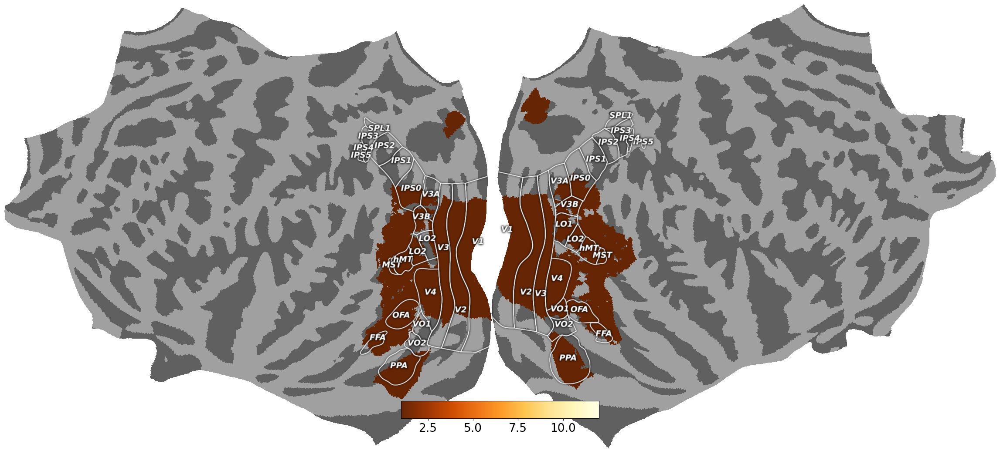

In [ ]:
"""Plot data on a flattened brain surface using pycortex.

"""

lh_challenge = lh_challenge_rois[:24].sum(0).numpy().astype(float)
lh_challenge[lh_challenge == 0] = np.nan

rh_challenge = rh_challenge_rois[:24].sum(0).numpy().astype(float)
rh_challenge[rh_challenge == 0] = np.nan

import os
from copy import copy
import numpy as np
from matplotlib import pyplot as plt
import cortex
import cortex.polyutils

# =============================================================================
# Map the data to fsaverage space
# =============================================================================
# pycortex requires data in fsaverage space, so here you map the vertices from
# Challenge space into fsaverage space. The voxels not used in the Challenge
# are given NaN values, so that pycortex ignores them for the plotting.
# "ls_scores" and "rh_scores" are lists with 8 elements, one for each subject.
# These elements consist of vectors of length N, where N is the vertex amount
# for each subject and hemisphere, and each vector component consists of the
# prediction accuracy for that vertex.

#challenge_data_dir = '../algonauts_2023_challenge_data'
challenge_data_dir = '/engram/nklab/algonauts/algonauts_2023_challenge_data/'
lh_fsaverage = []
rh_fsaverage = []
subjects = [1]
for s, sub in enumerate(subjects):
    lh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
        'roi_masks', 'lh.all-vertices_fsaverage_space.npy')
    rh_mask_dir = os.path.join(challenge_data_dir, 'subj'+format(sub, '02'),
        'roi_masks', 'rh.all-vertices_fsaverage_space.npy')
    lh_fsaverage_all_vertices = np.load(lh_mask_dir)
    rh_fsaverage_all_vertices = np.load(rh_mask_dir)
    lh_fsavg = np.empty((len(lh_fsaverage_all_vertices)))
    lh_fsavg[:] = np.nan
    lh_fsavg[np.where(lh_fsaverage_all_vertices)[0]] = lh_challenge #lh_challenge_rois[:24].sum(0) #lh_scores[s]
    lh_fsaverage.append(copy(lh_fsavg))
    rh_fsavg = np.empty((len(rh_fsaverage_all_vertices)))
    rh_fsavg[:] = np.nan
    rh_fsavg[np.where(rh_fsaverage_all_vertices)[0]] = rh_challenge #rh_scores[s]
    rh_fsaverage.append(copy(rh_fsavg))
    
    break

# Average the scores across subjects
lh_fsaverage = np.nanmean(lh_fsaverage, 0)
rh_fsaverage = np.nanmean(rh_fsaverage, 0)


# =============================================================================
# Plot parameters for colorbar
# =============================================================================
plt.rc('xtick', labelsize=19)
plt.rc('ytick', labelsize=19)


# =============================================================================
# Plot the results on brain surfaces
# =============================================================================
subject = 'fsaverage'
data = np.append(lh_fsaverage, rh_fsaverage)*10
data = np.clip(data, 0, 1)
vertex_data = cortex.Vertex(data, subject, cmap='YlOrBr_r', vmin=1, vmax=12)
cortex.quickshow(vertex_data, with_curvature=True)
#plt.savefig('images/chellenge_area.svg', dpi=300) 
plt.show()



In [ ]:
from nilearn import datasets
from nilearn import plotting
import os
import numpy as np
hemisphere = 'left' #@param ['left', 'right'] {allow-input: true}

lh_challenge = lh_challenge_rois[:24].sum(0).numpy().astype(float)
lh_challenge[lh_challenge == 0] = 0

rh_challenge = rh_challenge_rois[:24].sum(0).numpy().astype(float)
rh_challenge[rh_challenge == 0] = 0

data_dir = '/engram/nklab/algonauts/algonauts_2023_challenge_data/'
data_dir = os.path.join(data_dir, 'subj01')
# Load the brain surface map of all vertices
roi_dir = os.path.join(data_dir, 'roi_masks',
    hemisphere[0]+'h.all-vertices_fsaverage_space.npy')
fsaverage_all_vertices = np.load(roi_dir)

fsavg = np.empty((len(fsaverage_all_vertices)))
fsavg[:] = 0
fsavg[np.where(fsaverage_all_vertices)[0]] = lh_challenge #lh_challenge_rois[:24].sum(0) #lh_scores[s]

fsavg = np.clip(fsavg, 0, 1)
# rh_fsavg = np.empty((len(rh_fsaverage_all_vertices)))
# rh_fsavg[:] = np.nan
# rh_fsavg[np.where(rh_fsaverage_all_vertices)[0]] = rh_challenge 

# Create the interactive brain surface map
fsaverage = datasets.fetch_surf_fsaverage('fsaverage')
view = plotting.view_surf(
    surf_mesh=fsaverage['infl_'+hemisphere],
    surf_map=fsavg, # fsaverage_all_vertices,
    bg_map=fsaverage['sulc_'+hemisphere],
    threshold=1e-14,
    cmap='Reds',
    colorbar=False,
    title='All vertices, '+hemisphere+' hemisphere'
    )
view

## VPT experiments (`scripts/run_vpt_experiments.sh`)

Evaluate the four experiment groups produced by `bash scripts/run_vpt_experiments.sh`:

- `exp1` baseline linear      -> `dinov2_q_linear`
- `exp2` baseline transformer -> `dinov2_q_transformer`
- `exp3` shared VPT + decoder -> `dinov2_q_vpt-shared-decoder-prompt-shared-K{1,5,10}`
- `exp4` per-ROI VPT + linear -> `dinov2_q_vpt-per_roi-linear-prompt-shared-K1`

Each is a single run (run=1) at `enc_output_layer=1`, `subj=1`, `readout_res=rois_all`.


In [ ]:
# Evaluate every VPT experiment dir and collect ROI-wise correlations.
vpt_experiments = [
    ('exp1_linear',           'dinov2_q_linear'),
    ('exp2_transformer',      'dinov2_q_transformer'),
    ('exp3_vpt_shared_K1',    'dinov2_q_vpt-shared-decoder-prompt-shared-K1'),
    ('exp3_vpt_shared_K5',    'dinov2_q_vpt-shared-decoder-prompt-shared-K5'),
    ('exp3_vpt_shared_K10',   'dinov2_q_vpt-shared-decoder-prompt-shared-K10'),
    ('exp4_vpt_per_roi_K1',   'dinov2_q_vpt-per_roi-linear-prompt-shared-K1'),
]

class _ExpArgs:
    def __init__(self, arch):
        self.arch = arch
        self.feature_name = None
        self.readout_res = 'rois_all'
        self.enc_output_layer = 1
        self.learn_reg = 0
        self.subjects = [1]
        self.runs = [1]
        self.split = 'test'
        self.measure = 'exp_var'
        self.verbose = 1
        self.plot_figs = 1
        self.save_fig = None
        self.save_mean_act = None
        self.save_ave = 0
        self.save_val_corr = 0

vpt_results = {}
for label, arch in vpt_experiments:
    print(f'\n=== {label}  ({arch}) ===')
    args = _ExpArgs(arch)
    lh_corr, rh_corr, lh_roi_corr, rh_roi_corr, roi_names, lay_res_dir, group_sizes = evaluate_model(args)
    vpt_results[label] = dict(
        arch=arch, lh_corr=lh_corr, rh_corr=rh_corr,
        lh_roi=lh_roi_corr, rh_roi=rh_roi_corr,
        roi_names=roi_names, group_sizes=group_sizes,
        lay_res_dir=lay_res_dir,
    )


In [ ]:
# Side-by-side comparison: mean (LH+RH) noise-ceiling-normalised exp_var,
# overall and per ROI cluster.
labels   = list(vpt_results.keys())
clusters = ['visuals', 'bodies', 'faces', 'places', 'words', 'All areas']

mean_overall = []
per_cluster  = {c: [] for c in clusters}
for lbl in labels:
    r = vpt_results[lbl]
    rn = r['roi_names']
    lh_means = [np.nan_to_num(np.array(x), nan=0.0).mean() for x in r['lh_roi']]
    rh_means = [np.nan_to_num(np.array(x), nan=0.0).mean() for x in r['rh_roi']]
    combined = [(a + b) / 2 for a, b in zip(lh_means, rh_means)]
    mean_overall.append(combined[-1])
    for c in clusters:
        if c in rn:
            per_cluster[c].append(combined[rn.index(c)])
        else:
            per_cluster[c].append(np.nan)

fig, ax = plt.subplots(figsize=(14, 6))
plt.rcParams.update({'font.size': 14})
x = np.arange(len(labels))
width = 0.12
for i, c in enumerate(clusters):
    ax.bar(x + (i - len(clusters)/2) * width, per_cluster[c], width, label=c)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_ylabel('mean exp_var (LH+RH)/2')
ax.set_title('VPT experiments: per-cluster encoding accuracy (subj 1, layer 1, run 1)')
ax.legend(loc='best', ncol=3, fontsize=11)
plt.tight_layout()
os.makedirs('./images', exist_ok=True)
fig.savefig('./images/vpt_experiments_compare.png', dpi=200, bbox_inches='tight')
plt.show()

print('Overall (All areas) exp_var:')
for lbl, v in zip(labels, mean_overall):
    print(f'  {lbl:30s}  {v:.4f}')
